# Food Calorie Prediction from Images

This notebook implements a Convolutional Neural Network (CNN) model to predict the calorie content of food items from images. We'll use the NutritionVerse-Real dataset, which contains 889 images of 251 distinct dishes across 45 unique food types.

## Project Structure
1. Dataset Download & Exploration
2. Data Preprocessing & Augmentation 
3. CNN Model Architecture Design
4. Model Training & Evaluation
5. Gradio Interface Integration

Let's begin!

## 1. Environment Setup & Dataset Download

First, let's install the necessary packages and download the dataset from Kaggle.

In [1]:
# Install required packages
!pip install tensorflow numpy pandas matplotlib seaborn scikit-learn kaggle gradio pillow opencv-python

# Set up Kaggle API credentials (you need to upload your kaggle.json file)
import os
import json

# Uncomment the following if you're in Google Colab
# uploaded = files.upload()  # Upload kaggle.json
# os.makedirs('/root/.kaggle', exist_ok=True)
# with open('/root/.kaggle/kaggle.json', 'w') as f:
#     f.write(json.dumps(json.loads(next(iter(uploaded.values())).decode())))
# os.chmod('/root/.kaggle/kaggle.json', 600)

# For local environment, ensure your kaggle.json is in ~/.kaggle/ with proper permissions


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python -m pip install --upgrade pip


In [2]:
# Download the NutritionVerse-Real dataset
# !kaggle datasets download -d nutritionverse/nutritionverse-real --force
# !unzip -q nutritionverse-real.zip -d nutritionverse-data

## 2. Data Exploration & Understanding

Let's explore the dataset structure and examine some sample images and metadata.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import json

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
metadata_path = os.path.join(base_path, 'nutritionverse_dish_metadata3.csv')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

print(f"COCO metadata loaded with {len(coco_data['images'])} images and {len(coco_data['annotations'])} annotations")

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])
print("COCO images structure:")
print(coco_images.columns.tolist())

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")

# Load dataset splits if available
if os.path.exists(splits_path):
    splits_df = pd.read_csv(splits_path)
    print(f"Dataset splits loaded with {len(splits_df)} entries")
    print(f"Split distribution: {splits_df['category'].value_counts().to_dict()}")
else:
    print("Dataset splits file not found. Will use random splitting.")
    splits_df = None

# Load metadata
metadata_df = pd.read_csv(metadata_path)

# Display first few rows of metadata
print("Dataset Metadata Overview:")
print(f"Total entries: {len(metadata_df)}")
metadata_df.head()

COCO metadata loaded with 905 images and 4392 annotations
COCO images structure:
['id', 'license', 'file_name', 'height', 'width', 'date_captured']
Created mapping for 905 image IDs to filenames
Dataset splits loaded with 889 entries
Split distribution: {'Train': 624, 'Val': 265}


In [4]:
# add category to annotation df
annotation = coco_data['annotations']
category = coco_data['categories']
#each annotation consist of id, image_id, category_id, bbox, area, and segmentation(array of array )

for a in annotation:
    a['category'] = category[a['category_id']]['name']

# Visualizing image and segmentation

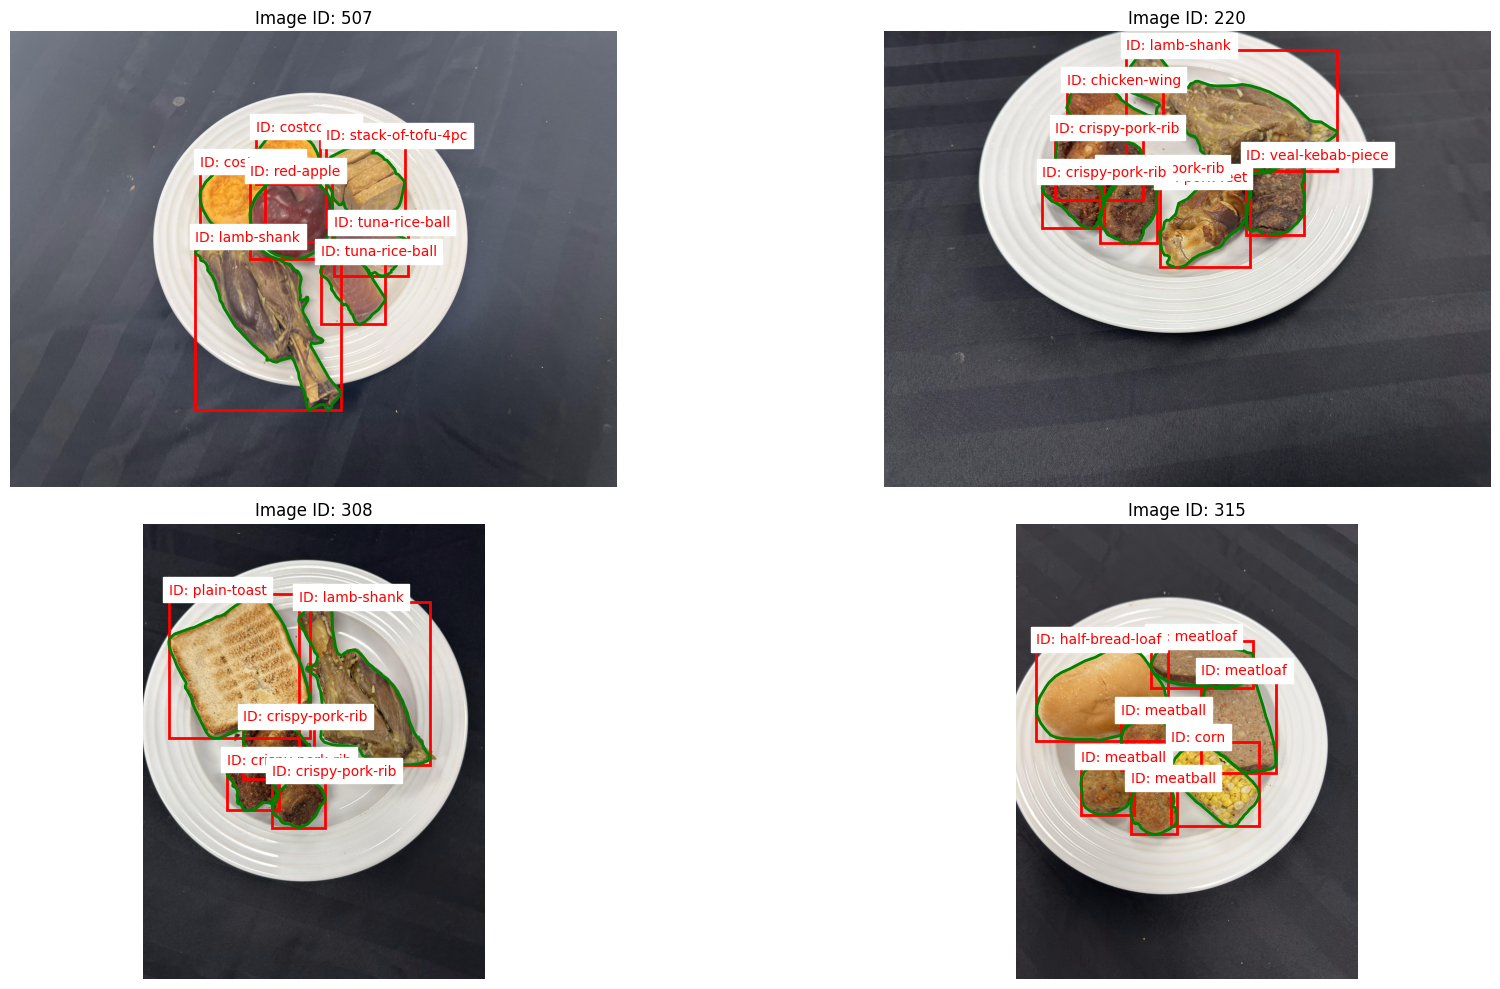

In [5]:
import matplotlib.patches as patches
import random
# Function to visualize image segmentation with labels
def visualize_segmentation_with_labels(image_ids, coco_data, image_id_to_filename, images_path):
    plt.figure(figsize=(20, 10))
    
    for i, img_id in enumerate(image_ids):
        # Get the filename for this image ID
        filename = image_id_to_filename[img_id]
        img_path = os.path.join(images_path, filename)
        
        # Load the image
        img = Image.open(img_path)
        
        # Get annotations for this image
        annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
        
        # Plot the image
        ax = plt.subplot(2, 2, i + 1)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Image ID: {img_id}")
        
        # Add bounding boxes, segmentation, and labels
        for ann in annotations:
            bbox = ann['bbox']
            segmentation = ann['segmentation']
            category = ann['category']
            
            # Draw bounding box
            rect = patches.Rectangle(
                (bbox[0], bbox[1]), bbox[2], bbox[3],
                linewidth=2, edgecolor='r', facecolor='none'
            )
            ax.add_patch(rect)
            
            # Add label for category_id
            ax.text(
                bbox[0], bbox[1] - 5, f"ID: {category}",
                color='red', fontsize=10, backgroundcolor='white'
            )
            
            # Draw segmentation (if available)
            for seg in segmentation:
                poly = np.array(seg).reshape((-1, 2))
                ax.plot(poly[:, 0], poly[:, 1], 'g-', linewidth=2)
    
    plt.tight_layout()
    plt.show()

# Select 4 random image IDs
selected_image_ids = random.sample(list(image_id_to_filename.keys()), 4)

# Visualize segmentation with labels
visualize_segmentation_with_labels(selected_image_ids, coco_data, image_id_to_filename, images_path)

In [6]:
# align metadata df with the images
# Extract file names from COCO dataset and create mapping to dish_id
image_files = os.listdir(images_path)
valid_images = []
image_dish_ids = {}

# Map images to dish_id based on filename pattern (dish_XX_...)
for filename in image_files:
    if filename.startswith('dish_'):
        try:
            # Extract dish_id from filename
            parts = filename.split('_')
            if len(parts) > 1:
                dish_id = int(parts[1])
                if dish_id not in image_dish_ids:
                    image_dish_ids[dish_id] = []
                image_dish_ids[dish_id].append(filename)
                valid_images.append(True)
            else:
                valid_images.append(False)
        except (ValueError, IndexError):
            valid_images.append(False)
    else:
        valid_images.append(False)

# Create a new column for image paths in metadata_df
metadata_df['image_names'] = metadata_df['dish_id'].apply(
    lambda dish_id: image_dish_ids.get(dish_id, [])
)

# Add a flag indicating if valid images were found
metadata_df['valid_image'] = metadata_df['image_names'].apply(lambda x: len(x) > 0)

# Print summary
print(f"Found valid images for {metadata_df['valid_image'].sum()} out of {len(metadata_df)} dishes")
print(f"Total images mapped: {sum(len(imgs) for imgs in image_dish_ids.values())}")

# Display dishes without valid images
if not all(metadata_df['valid_image']):
    print("\nDishes without mapped images:")
    print(metadata_df[~metadata_df['valid_image']]['dish_id'].tolist())
print(metadata_df.iloc[23]['image_names'])
print(type(metadata_df.iloc[23]['image_names']))
# Remove rows without valid images
metadata_df = metadata_df[metadata_df['valid_image']]

# Reset the index after filtering
metadata_df.reset_index(drop=True, inplace=True)

# Print the updated metadata_df
print(f"Updated metadata_df with {len(metadata_df)} rows containing valid images.")
metadata_df.head()

NameError: name 'metadata_df' is not defined

# Food Detection with CNN

In this section, we'll train a CNN model to detect and classify different food items in images using the segmentation data from the dataset. We'll use the segmented regions of food items along with their category labels for training.

In [ ]:
# Import necessary libraries for image processing and model building
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import cv2
import numpy as np
from tqdm import tqdm
import random
import pandas as pd

# Define constants
IMG_SIZE = 224  # Input size for MobileNetV2
BATCH_SIZE = 32
EPOCHS = 15
NUM_CLASSES = len(coco_data['categories'])

# Function to extract and preprocess food regions based on segmentation
def extract_food_regions(image_ids, coco_data, image_id_to_filename, images_path):
    X = []  # Cropped food images
    y = []  # Food category labels
    
    progress_bar = tqdm(image_ids)
    for img_id in progress_bar:
        try:
            # Get the filename for this image ID
            filename = image_id_to_filename[img_id]
            img_path = os.path.join(images_path, filename)
            
            # Load the image
            image = cv2.imread(img_path)
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # Get annotations for this image
            annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
            
            for ann in annotations:
                category_id = ann['category_id']
                bbox = ann['bbox']  # [x, y, width, height]
                
                # Extract region using bounding box
                x, y_coord, w, h = [int(v) for v in bbox]
                
                # Ensure coordinates are within image boundaries
                x = max(0, x)
                y_coord = max(0, y_coord)
                w = min(w, image.shape[1] - x)
                h = min(h, image.shape[0] - y_coord)
                
                if w <= 0 or h <= 0:
                    continue
                
                # Extract the region
                food_region = image[y_coord:y_coord+h, x:x+w]
                
                # Resize to standard size
                food_region = cv2.resize(food_region, (IMG_SIZE, IMG_SIZE))
                
                # Normalize pixel values
                food_region = food_region / 255.0
                
                # Add to dataset
                X.append(food_region)
                y.append(category_id)
                
        except Exception as e:
            print(f"Error processing image {img_id}: {e}")
    
    return np.array(X), np.array(y)


# Read the CSV file with train-test split information
print("Loading train-test split from CSV file...")
try:
    split_df = pd.read_csv('nutritionverse-data/nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv', header=None)
    split_df.columns = ['file_name', 'category']
    
    # Create dictionaries for train and test splits
    train_filenames = set(split_df[split_df['split'] == 'Train']['file_name'])
    test__filenames = set(split_df[split_df['split'] == 'Test']['file_name'])
    
    print(f"Found {len(train_filenames)} training images and {len(test__filenames)} test images in the split file")
except Exception as e:
    print(f"Error loading split file: {e}")
    print("Will fall back to random train-test split")
    train_filenames = None
    test__filenames = None

# Function to split the dataset and extract food regions
def prepare_train_test_data(coco_data, image_id_to_filename, images_path, train_filenames, test_filenames):
    # Get all image IDs
    all_image_ids = [img['id'] for img in coco_data['images']]
    
    # Get train and test image IDs based on predefined splits
    if train_filenames is not None and test_filenames is not None:
        train_image_ids = [img_id for img_id in all_image_ids if image_id_to_filename[img_id] in train_filenames]
        test_image_ids = [img_id for img_id in all_image_ids if image_id_to_filename[img_id] in test_filenames]
    else:
        # If no predefined splits, randomly split the dataset
        random.shuffle(all_image_ids)
        split_index = int(0.8 * len(all_image_ids))  # 80% for training, 20% for testing
        train_image_ids = all_image_ids[:split_index]
        test_image_ids = all_image_ids[split_index:]
    
    print(f"Using {len(train_image_ids)} training images and {len(test_image_ids)} testing images.")
    
    # Extract food regions for training and testing datasets
    print("Extracting food regions for training dataset...")
    X_train, y_train = extract_food_regions(train_image_ids, coco_data, image_id_to_filename, images_path)
    
    print("Extracting food regions for testing dataset...")
    X_test, y_test = extract_food_regions(test_image_ids, coco_data, image_id_to_filename, images_path)
    
    return X_train, y_train, X_test, y_test

# Prepare the train and test datasets
X_train, y_train, X_test, y_test = prepare_train_test_data(
    coco_data, image_id_to_filename, images_path, train_filenames, test__filenames
)

# Print dataset shapes
print(f"Training dataset: {X_train.shape}, {y_train.shape}")
print(f"Testing dataset: {X_test.shape}, {y_test.shape}")


2025-05-25 13:12:42.803618: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748178762.818668  433602 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748178762.823570  433602 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1748178762.834870  433602 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748178762.834881  433602 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748178762.834884  433602 computation_placer.cc:177] computation placer alr

Extracting food regions from 905 images...


100%|██████████| 905/905 [01:17<00:00, 11.75it/s]


Extracted 4306 food regions with shape (4306, 224, 224, 3)
Number of food categories: 44


In [ ]:
import logging
import time

TIMESTAMP = int(time.time())
# Create a dynamic log file name
log_file_name = f"training_log_E{EPOCHS}_B{BATCH_SIZE}_IMG{IMG_SIZE}_TIMEP{TIMESTAMP}.log"

# Configure logging
logging.basicConfig(
    filename=log_file_name,  # Use the dynamic log file name
    level=logging.INFO,  # Log level
    format='%(asctime)s - %(levelname)s - %(message)s'  # Log format
)

# Custom callback to log training progress
class TrainingLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        logging.info(
            f"Epoch {epoch + 1}: "
            f"loss = {logs.get('loss'):.4f}, "
            f"accuracy = {logs.get('accuracy'):.4f}, "
            f"val_loss = {logs.get('val_loss'):.4f}, "
            f"val_accuracy = {logs.get('val_accuracy'):.4f}"
        )
        print(
            f"Epoch {epoch + 1}: "
            f"loss = {logs.get('loss'):.4f}, "
            f"accuracy = {logs.get('accuracy'):.4f}, "
            f"val_loss = {logs.get('val_loss'):.4f}, "
            f"val_accuracy = {logs.get('val_accuracy'):.4f}"
        )

# Build a CNN model for food detection
def build_food_detection_model(num_classes):
    
    model = models.Sequential([
        # First convolutional block
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.MaxPooling2D((2, 2)),

        # Second convolutional block
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Third convolutional block
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Fourth convolutional block
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        # Flatten and fully connected layers
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.1),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model


strategy = tf.distribute.MirroredStrategy()

with strategy.scope():
    # Create and compile the model
    model = build_food_detection_model(num_classes)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

# Display model summary
model.summary()

# Data augmentation for training
datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Train the model
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=7, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.1, patience=2),
        TrainingLogger()
    ]
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)


I0000 00:00:1748178844.012491  433602 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 18446 MB memory:  -> device: 0, name: NVIDIA RTX 4000 Ada Generation, pci bus id: 0000:41:00.0, compute capability: 8.9
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,874,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 44)             │        22,572 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,287,916 (73.58 MB)

...

Epoch 2: loss = 2.0782, accuracy = 0.4688, val_loss = 12.7458, val_accuracy = 0.0248
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.4688 - loss: 2.0782 - val_accuracy: 0.0248 - val_loss: 12.7458 - learning_rate: 0.0010
Epoch 3/15


2025-05-25 13:15:41.816094: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node MultiDeviceIteratorGetNextFromShard}}]]
	 [[RemoteCall]]


47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.5187 - loss: 1.7668Epoch 3: loss = 1.6623, accuracy = 0.5492, val_loss = 4.5677, val_accuracy = 0.1788
47/47 ━━━━━━━━━━━━━━━━━━━━ 26s 545ms/step - accuracy: 0.5193 - loss: 1.7646 - val_accuracy: 0.1788 - val_loss: 4.5677 - learning_rate: 0.0010
Epoch 4/15
 1/47 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - accuracy: 0.5000 - loss: 1.5969Epoch 4: loss = 1.5969, accuracy = 0.5000, val_loss = 4.9892, val_accuracy = 0.1331
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5000 - loss: 1.5969 - val_accuracy: 0.1331 - val_loss: 4.9892 - learning_rate: 0.0010
Epoch 5/15


2025-05-25 13:16:08.626185: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node MultiDeviceIteratorGetNextFromShard}}]]
	 [[RemoteCall]]


47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 510ms/step - accuracy: 0.6097 - loss: 1.3632Epoch 5: loss = 1.3629, accuracy = 0.6064, val_loss = 3.6725, val_accuracy = 0.2724
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 534ms/step - accuracy: 0.6096 - loss: 1.3632 - val_accuracy: 0.2724 - val_loss: 3.6725 - learning_rate: 0.0010
Epoch 6/15
 1/47 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.7031 - loss: 1.0502Epoch 6: loss = 1.0502, accuracy = 0.7031, val_loss = 3.7005, val_accuracy = 0.2802
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7031 - loss: 1.0502 - val_accuracy: 0.2802 - val_loss: 3.7005 - learning_rate: 0.0010
Epoch 7/15
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 518ms/step - accuracy: 0.6333 - loss: 1.2787

In [ ]:
print("X")

In [ ]:
model.save("raw_4layer32_224Size_32bs_15E.h5")

# Inference

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import cv2
import pandas as pd
import random
from sklearn.preprocessing import LabelEncoder

def detect_food_in_image(image_path, model, label_encoder):
    # Load and preprocess the image
    image = cv2.imread(image_path)
    if image is None:
        return "Image not found."
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    original_image = image.copy()
    
    # For visualization
    plt.figure(figsize=(12, 12))
    plt.imshow(original_image)
    plt.title("Food Detection Results")
    
    results = []
    
    # Method 1: Contour-based detection
    # Convert to HSV color space for better color segmentation
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    
    # Apply Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(hsv_image, (5, 5), 0)
    
    # Use adaptive thresholding to find potential regions of interest
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    thresh = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
        cv2.THRESH_BINARY_INV, 11, 2
    )
    
    # Find contours in the thresholded image
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Filter contours by area to remove tiny regions
    min_area = image.shape[0] * image.shape[1] * 0.01  # 1% of image area
    significant_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]
    
    # Analyze each significant contour
    for i, contour in enumerate(significant_contours):
        # Get bounding rectangle
        x, y, w, h = cv2.boundingRect(contour)
        
        # Ensure the region is reasonably sized
        if w < 20 or h < 20:
            continue
            
        # Extract the region
        food_region = original_image[y:y+h, x:x+w]
        
        # Resize to standard size
        food_region_resized = cv2.resize(food_region, (IMG_SIZE, IMG_SIZE))
        
        # Normalize pixel values
        food_region_normalized = food_region_resized / 255.0
        
        # Predict
        prediction = model.predict(np.expand_dims(food_region_normalized, axis=0), verbose=0)
        predicted_class_idx = np.argmax(prediction)
        confidence = prediction[0][predicted_class_idx]
        
        # Filter predictions with low confidence
        if confidence < 0.4:
            continue
            
        # Convert to category name
        predicted_class = label_encoder.inverse_transform([predicted_class_idx])[0]
        category_name = next((cat['name'] for cat in coco_data['categories'] if cat['id'] == predicted_class), "Unknown")
        
        # Add to results
        results.append({
            'category': category_name,
            'confidence': float(confidence),
            'bbox': [x, y, w, h]
        })
        
        # Draw rectangle and label on the image
        rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor='r', facecolor='none')
        plt.gca().add_patch(rect)
        plt.text(x, y - 5, f"{category_name} ({confidence:.2f})", 
                 color='white', fontsize=12, backgroundcolor='red')
    
    # Method 2: Multi-scale sliding window detection
    # Run regardless of whether contours found anything, to improve detection of multiple foods
    print("Running sliding window detection for multiple food items...")
    
    # Define window sizes (relative to image size)
    window_sizes = [
        (image.shape[1]//2, image.shape[0]//2),  # Half image size
        (image.shape[1]//3, image.shape[0]//3),  # One-third size
        # (image.shape[1]//4, image.shape[0]//4)   # One-fourth size
    ]
    
    # Smaller step size to catch more food items (with overlap)
    step_size = min(image.shape[0], image.shape[1]) // 8
    
    # Track detection regions to avoid duplicates
    detection_heatmap = np.zeros((image.shape[0], image.shape[1]), dtype=np.float32)
    sliding_window_results = []
    
    # Process each window size
    for win_w, win_h in window_sizes:
        # Skip if window is too small
        if win_w < 50 or win_h < 50:
            continue
            
        for y in range(0, image.shape[0] - win_h, step_size):
            for x in range(0, image.shape[1] - win_w, step_size):
                # Extract window
                window = original_image[y:y+win_h, x:x+win_w]
                
                # Resize to standard size
                window_resized = cv2.resize(window, (IMG_SIZE, IMG_SIZE))
                
                # Normalize pixel values
                window_normalized = window_resized / 255.0
                
                # Predict
                prediction = model.predict(np.expand_dims(window_normalized, axis=0), verbose=0)
                predicted_class_idx = np.argmax(prediction)
                confidence = prediction[0][predicted_class_idx]
                
                # Filter predictions with low confidence
                if confidence < 0.5:
                    continue
                    
                # Convert to category name
                predicted_class = label_encoder.inverse_transform([predicted_class_idx])[0]
                category_name = next((cat['name'] for cat in coco_data['categories'] if cat['id'] == predicted_class), "Unknown")
                
                # Add to sliding window results
                sliding_window_results.append({
                    'category': category_name,
                    'confidence': float(confidence),
                    'bbox': [x, y, win_w, win_h]
                })
                
                # Add to heatmap for later NMS
                detection_heatmap[y:y+win_h, x:x+win_w] += confidence
    
    # Non-maximum suppression to eliminate overlapping windows
    # Sort sliding window results by confidence (highest first)
    sliding_window_results.sort(key=lambda x: x['confidence'], reverse=True)
    
    # Keep track of which results to keep
    keep_results = []
    
    # Simple NMS implementation
    for i, current in enumerate(sliding_window_results):
        # Skip if this window was already suppressed
        if current in keep_results:
            continue
            
        # Current window coordinates
        x1, y1, w1, h1 = current['bbox']
        x2, y2 = x1 + w1, y1 + h1
        
        # Keep this window
        keep_results.append(current)
        
        # Check against all other windows
        for j, other in enumerate(sliding_window_results):
            if i == j or other in keep_results:
                continue
                
            # Other window coordinates
            x3, y3, w2, h2 = other['bbox']
            x4, y4 = x3 + w2, y3 + h2
            
            # Calculate intersection area
            x_overlap = max(0, min(x2, x4) - max(x1, x3))
            y_overlap = max(0, min(y2, y4) - max(y1, y3))
            intersection = x_overlap * y_overlap
            
            # Calculate union area
            area1 = w1 * h1
            area2 = w2 * h2
            union = area1 + area2 - intersection
            
            # Calculate IoU (Intersection over Union)
            iou = intersection / union if union > 0 else 0
            
            # If there's significant overlap and same category, suppress the lower confidence window
            if iou > 0.5 and current['category'] == other['category']:
                # Don't add other to keep_results - it's being suppressed
                pass
    
    # Add the filtered sliding window results to the overall results
    for result in keep_results:
        x, y, w, h = result['bbox']
        category_name = result['category']
        confidence = result['confidence']
        
        # Add to results if not already detected by contour method
        # (Simple check - if there's no major overlap with existing results)
        should_add = True
        for existing in results:
            ex, ey, ew, eh = existing['bbox']
            if (x < ex + ew and x + w > ex and 
                y < ey + eh and y + h > ey and
                existing['category'] == category_name):
                should_add = False
                break
                
        if should_add:
            results.append(result)
            
            # Draw rectangle and label on the image
            rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor='b', facecolor='none')
            plt.gca().add_patch(rect)
            plt.text(x, y - 5, f"{category_name} ({confidence:.2f})", 
                     color='white', fontsize=12, backgroundcolor='blue')
    
    # Display results
    plt.axis('off')
    plt.show()
    
    print(f"Detected {len(results)} food items in total.")
    return results


# Define constants
IMG_SIZE = 224  # Input size for MobileNetV2
BATCH_SIZE = 64
EPOCHS = 15

# Load the saved model
model_path = "224_15_Epoch_raw_new.keras"
food_detection_model = tf.keras.models.load_model(model_path)

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")


category = coco_data['categories']
# Extract only the 'id' values from the categories
category_ids = [cat['id'] for cat in category]

# Initialize and fit the LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(category_ids)


# Test the detection on a sample image
sample_image_id = random.choice(list(image_id_to_filename.keys()))
sample_filename = image_id_to_filename[sample_image_id]
sample_image_path = os.path.join(images_path, sample_filename)

print(f"Testing food detection on image: {sample_filename}")

# Predict food categories
detected_foods = detect_food_in_image(sample_image_path, food_detection_model, label_encoder)

print("Detected food items:")
for i, food in enumerate(detected_foods):
    print(f"{i+1}. {food['category']} (Confidence: {food['confidence']:.2f})")

